# FoodieAnalytics: Food Delivery Analytics and Restaurant Recommendation System using Big Data
## Stage 2 – Data Cleaning and Preprocessing of Zomato Dataset

---

### Section 1: Introduction

#### 1.1 What Data Preprocessing Means
**Data preprocessing** is the foundational phase in the Big Data lifecycle where raw, heterogeneous, and often noisy data is transformed into a clean, structured, and syntactically consistent format suitable for analytical querying, distributed computing, and machine learning models. In raw industrial datasets, issues such as missing attributes, irregular string encodings, conflicting data types, redundant records, and unstandardized categorical labels corrupt downstream modeling and yield misleading aggregations.

#### 1.2 Importance of Data Cleaning in Big Data Analytics
In Big Data architectures (such as Apache Hadoop, Apache Spark, and Apache Hive), data quality is paramount (*"garbage in, garbage out"*). Distributed data processing engines partition data across worker clusters. Unhandled null pointers, malformed numerical fields (e.g., strings with currency symbols or commas), and duplicate records cause expensive stage failures, memory skew, biased aggregations, and degraded recommendation system performance. Cleaning the dataset upstream guarantees reproducibility, computational efficiency, and analytical integrity across downstream distributed systems.

#### 1.3 Why Restaurant Data Requires Cleaning
Restaurant catalog datasets collected via web scrapers and API integrations—such as this Zomato Bangalore dataset—exhibit specific anomalies:
* **Complex Rating Encodings**: Consumer ratings are recorded as fractional text strings (e.g., `'4.1/5'`), along with placeholder markers such as `'NEW'` for newly inaugurated restaurants and `'-'` for unrated establishments.
* **Formatted Numeric Fields**: Cost indicators (`approx_cost(for two people)`) are stored as strings containing thousands separators (e.g., `'1,200'`).
* **Multi-valued and Inconsistent Cuisines**: The `cuisines` column contains multi-cuisine comma-separated entries with irregular spacing, arbitrary casing (`'chinese'` vs `'Chinese'`), and duplicate tags.
* **Scraper Pagination Duplicates**: Web scraping pipelines often generate duplicate records due to pagination overlaps and tracking query parameters in URLs.
* **Granular Locality Labels**: Localities and delivery zones feature subtle variations that require standardization without erroneously conflating distinct urban blocks.

#### 1.4 Objectives of this Preprocessing Operation
1. **Audit & Traceability**: Conduct a rigorous baseline quality audit and establish an explicit column name mapping from raw headers to standardized `snake_case` identifiers.
2. **Deduplication**: Identify and eliminate redundant scraping duplicate records across all substantive restaurant features without deleting valid multi-zone listings.
3. **Principled Missing Value Remediation**: Apply domain-justified strategies to handle missing values, distinguishing between genuine missingness and unrated entities without fabricating data.
4. **Textual Standardization**: Standardize multi-valued cuisine strings, strip erratic whitespace, remove intra-restaurant cuisine duplicates, and harmonize locality names.
5. **Type Casting & Range Validation**: Safely cast ratings, costs, votes, and binary flags into native numerical and boolean types with boundary validation.
6. **Persistence & Verification**: Save the cleaned dataset to `dataset/processed/cleaned_zomato.csv` and export verified data quality comparison reports and visualizations to `reports/data_quality/`.


---
### Section 2: Import Libraries

We import essential data manipulation, mathematical computing, filesystem handling, and visualization libraries. We also connect to our modular `preprocessing.clean_data` module for reusable cleaning functions.


In [1]:
import sys
import os
from pathlib import Path
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure project root is accessible in Python path for modular imports
project_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from preprocessing import clean_data

# Visualization configurations
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 120
sns.set_palette("tab10")

print("==================================================================")
print("SUCCESS: All required libraries and modular utilities imported!")
print("==================================================================")
print(f"Python Runtime     : {sys.version.split()[0]}")
print(f"Pandas Version     : {pd.__version__}")
print(f"NumPy Version      : {np.__version__}")
print(f"Matplotlib Version : {plt.matplotlib.__version__}")
print(f"Seaborn Version    : {sns.__version__}")
print(f"Project Root       : {project_root}")
print("==================================================================")


SUCCESS: All required libraries and modular utilities imported!
Python Runtime     : 3.12.11
Pandas Version     : 3.1.0
NumPy Version      : 2.5.4
Matplotlib Version : 3.11.2
Seaborn Version    : 0.13.2
Project Root       : C:\BDA-miniproject


---
### Section 3: Load Original Dataset

We construct a reliable relative path to `dataset/raw/zomato.csv` and load the raw dataset with UTF-8 encoding. We verify that the original dataset is loaded into a working DataFrame and remains untouched on disk.


In [2]:
# Resolve relative path to raw dataset
raw_csv_path = project_root / "dataset" / "raw" / "zomato.csv"
reports_quality_dir = project_root / "reports" / "data_quality"
processed_dir = project_root / "dataset" / "processed"

reports_quality_dir.mkdir(parents=True, exist_ok=True)
processed_dir.mkdir(parents=True, exist_ok=True)

print(f"Loading raw dataset from: {raw_csv_path}")
print(f"Raw File Size: {raw_csv_path.stat().st_size / (1024 * 1024):.2f} MB")

df_raw = pd.read_csv(raw_csv_path, encoding='utf-8')

print("\n" + "=" * 66)
print("                    RAW DATASET DIMENSIONS                        ")
print("=" * 66)
print(f"Total Rows (Records)    : {df_raw.shape[0]:,}")
print(f"Total Columns (Features): {df_raw.shape[1]}")
print(f"Dataset Shape Tuple     : {df_raw.shape}")
print("=" * 66)

print("\nFirst 5 Records of Original Dataset:")
display(df_raw.head(5))

print("\nColumn Names and Data Types:")
print("-" * 66)
for col, dtype in zip(df_raw.columns, df_raw.dtypes):
    print(f" - {col:<32} : {dtype}")


Loading raw dataset from: C:\BDA-miniproject\dataset\raw\zomato.csv
Raw File Size: 547.48 MB



                    RAW DATASET DIMENSIONS                        
Total Rows (Records)    : 51,717
Total Columns (Features): 17
Dataset Shape Tuple     : (51717, 17)

First 5 Records of Original Dataset:


,url,address,name,online_order,book_table,rate,votes,phone,location,rest_type,dish_liked,cuisines,approx_cost(for two people),reviews_list,menu_item,listed_in(type),listed_in(city)
0,https://www.zomato.com/bangalore/jalsa-banasha...,"942, 21st Main Road, 2nd Stage, Banashankari, ...",Jalsa,Yes,Yes,4.1/5,775,080 42297555\r\n+91 9743772233,Banashankari,Casual Dining,"Pasta, Lunch Buffet, Masala Papad, Paneer Laja...","North Indian, Mughlai, Chinese",800,"[('Rated 4.0', 'RATED\n A beautiful place to ...",[],Buffet,Banashankari
1,https://www.zomato.com/bangalore/spice-elephan...,"2nd Floor, 80 Feet Road, Near Big Bazaar, 6th ...",Spice Elephant,Yes,No,4.1/5,787,080 41714161,Banashankari,Casual Dining,"Momos, Lunch Buffet, Chocolate Nirvana, Thai G...","Chinese, North Indian, Thai",800,"[('Rated 4.0', 'RATED\n Had been here for din...",[],Buffet,Banashankari
2,https://www.zomato.com/SanchurroBangalore?cont...,"1112, Next to KIMS Medical College, 17th Cross...",San Churro Cafe,Yes,No,3.8/5,918,+91 9663487993,Banashankari,"Cafe, Casual Dining","Churros, Cannelloni, Minestrone Soup, Hot Choc...","Cafe, Mexican, Italian",800,"[('Rated 3.0', ""RATED\n Ambience is not that ...",[],Buffet,Banashankari
3,https://www.zomato.com/bangalore/addhuri-udupi...,"1st Floor, Annakuteera, 3rd Stage, Banashankar...",Addhuri Udupi Bhojana,No,No,3.7/5,88,+91 9620009302,Banashankari,Quick Bites,Masala Dosa,"South Indian, North Indian",300,"[('Rated 4.0', ""RATED\n Great food and proper...",[],Buffet,Banashankari
4,https://www.zomato.com/bangalore/grand-village...,"10, 3rd Floor, Lakshmi Associates, Gandhi Baza...",Grand Village,No,No,3.8/5,166,+91 8026612447\r\n+91 9901210005,Basavanagudi,Casual Dining,"Panipuri, Gol Gappe","North Indian, Rajasthani",600,"[('Rated 4.0', 'RATED\n Very good restaurant ...",[],Buffet,Banashankari



Column Names and Data Types:
------------------------------------------------------------------
 - url                              : str
 - address                          : str
 - name                             : str
 - online_order                     : str
 - book_table                       : str
 - rate                             : str
 - votes                            : int64
 - phone                            : str
 - location                         : str
 - rest_type                        : str
 - dish_liked                       : str
 - cuisines                         : str
 - approx_cost(for two people)      : str
 - reviews_list                     : str
 - menu_item                        : str
 - listed_in(type)                  : str
 - listed_in(city)                  : str


---
### Section 4: Initial Data Quality Assessment

Before executing any transformations, we perform a comprehensive quality audit of all 17 features:
* Identifying missing value counts and null percentages.
* Quantifying unique values per attribute.
* Counting exact duplicate rows.
* Persisting the assessment table to `reports/data_quality/before_cleaning.csv`.


In [3]:
# Generate initial quality report using the preprocessing module
before_cleaning_path = reports_quality_dir / "before_cleaning.csv"
quality_before_df = clean_data.generate_initial_quality_report(df_raw, before_cleaning_path)

print("=" * 66)
print("              INITIAL DATA QUALITY AUDIT TABLE                    ")
print("=" * 66)
display(quality_before_df)

print(f"\nInitial quality assessment successfully saved to:")
print(f" -> {before_cleaning_path.relative_to(project_root)}")


[2/9] Initial quality assessment saved to: C:\BDA-miniproject\reports\data_quality\before_cleaning.csv
              INITIAL DATA QUALITY AUDIT TABLE                    


,column_name,data_type,total_records,non_null_count,missing_count,missing_percentage,unique_values_count,sample_value
0,url,str,51717,51717,0,0.00,51717,https://www.zomato.com/bangalore/jals...
1,address,str,51717,51717,0,0.00,11495,"942, 21st Main Road, 2nd Stage, Banas..."
2,name,str,51717,51717,0,0.00,8792,Jalsa
3,online_order,str,51717,51717,0,0.00,2,Yes
4,book_table,str,51717,51717,0,0.00,2,Yes
5,rate,str,51717,43942,7775,15.03,64,4.1/5
6,votes,int64,51717,51717,0,0.00,2328,775
7,phone,str,51717,50509,1208,2.34,14926,080 42297555\r\n+91 9743772233
8,location,str,51717,51696,21,0.04,93,Banashankari
9,rest_type,str,51717,51490,227,0.44,93,Casual Dining



Initial quality assessment successfully saved to:
 -> reports\data_quality\before_cleaning.csv


---
### Section 5: Standardize Column Names

Standardizing attribute names to lowercase `snake_case` eliminates leading/trailing whitespace, replaces parenthetical expressions and punctuation with underscores, and prevents naming conflicts. 

An explicit column mapping table is created and exported to `reports/data_quality/column_name_mapping.csv` to ensure complete schema traceability.


In [4]:
# Standardize column names and generate traceability mapping
mapping_path = reports_quality_dir / "column_name_mapping.csv"
df, mapping_df = clean_data.standardize_column_names(df_raw, mapping_path)

print("=" * 66)
print("             COLUMN NAME STANDARDIZATION MAPPING                  ")
print("=" * 66)
display(mapping_df)

print("\nStandardized Column Names in DataFrame:")
print(df.columns.tolist())
print(f"\nTraceability mapping exported to: {mapping_path.relative_to(project_root)}")


[3/9] Standardized 17 column names. Mapping saved to: C:\BDA-miniproject\reports\data_quality\column_name_mapping.csv
             COLUMN NAME STANDARDIZATION MAPPING                  


,original_column,standardized_column,original_data_type
0,url,url,str
1,address,address,str
2,name,name,str
3,online_order,online_order,str
4,book_table,book_table,str
5,rate,rate,str
6,votes,votes,int64
7,phone,phone,str
8,location,location,str
9,rest_type,rest_type,str



Standardized Column Names in DataFrame:
['url', 'address', 'name', 'online_order', 'book_table', 'rate', 'votes', 'phone', 'location', 'rest_type', 'dish_liked', 'cuisines', 'approx_cost_for_two_people', 'reviews_list', 'menu_item', 'listed_in_type', 'listed_in_city']

Traceability mapping exported to: reports\data_quality\column_name_mapping.csv


---
### Section 6: Handle Duplicate Records

We evaluate duplicate records at multiple granularities:
1. **Full 17-Column Exact Duplicates**: Zero rows in the raw dataset have identical URLs, as each URL string contains a unique session query parameter (`?context=...`).
2. **Substantive Content Duplicates (Excluding URL)**: Evaluates all 16 substantive restaurant features (name, address, online order, rate, votes, location, cuisines, cost, etc.). 
   * **40 duplicate records** are identified. These represent redundant entries produced by web scraper pagination overlap where the identical restaurant and listing were captured twice.
3. **Multi-zone Listings (`name` + `address`)**: A physical restaurant delivering across adjacent zones (e.g. BTM and Koramangala) possesses multiple entries under distinct `listed_in_city` zones. In strict accordance with guidelines, these genuine business listings are preserved.


In [5]:
# Execute deduplication
df, dup_metrics = clean_data.handle_duplicates(df)

print("=" * 66)
print("                    DUPLICATION AUDIT SUMMARY                     ")
print("=" * 66)
print(f"Total Records Before Deduplication     : {len(df_raw):,}")
print(f"Full 17-Column Exact Duplicates        : {dup_metrics['full_duplicates']:,}")
print(f"Redundant Scrape Duplicates (Excl URL) : {dup_metrics['content_duplicates']:,}")
print(f"Total Duplicate Rows Removed           : {dup_metrics['removed_count']:,}")
print(f"Records Remaining After Deduplication  : {dup_metrics['remaining_count']:,}")
print("=" * 66)


[4/9] Duplicate Analysis:
      Full 17-column exact duplicates : 0
      Duplicates across content cols  : 40
      Duplicate rows removed          : 40
      Records remaining               : 51,677
                    DUPLICATION AUDIT SUMMARY                     
Total Records Before Deduplication     : 51,717
Full 17-Column Exact Duplicates        : 0
Redundant Scrape Duplicates (Excl URL) : 40
Total Duplicate Rows Removed           : 40
Records Remaining After Deduplication  : 51,677


---
### Section 7: Handle Missing Values

We implement principled, domain-appropriate missing value handling strategies:

| Column | Missing Before | Cleaning Strategy | Values Affected | Missing Remaining | Justification |
| :--- | :---: | :--- | :---: | :---: | :--- |
| `name` | 0 | Validation check | 0 | 0 | Critical entity identifier; 100% complete in raw data. |
| `location` | 21 | Drop unusable records | 21 rows removed | 0 | Unusable records with missing locality, 0 votes, NaN ratings, and NaN costs. |
| `cuisines` | 45 | Impute with `'Not Specified'` | 24 remaining | 0 | Prevents discarding valid restaurants due to missing cuisine tag. |
| `rest_type` | 227 | Impute with `'Not Specified'` | 206 remaining | 0 | Descriptive format label; retains full catalog record. |
| `dish_liked` | 28,078 | Impute with `'Not Specified'` | 28,028 remaining | 0 | Prevents deleting over 54% of valid restaurant records. |
| `phone` | 1,208 | Impute with `'Not Provided'` | 1,186 remaining | 0 | Non-essential contact info; preserves catalog records. |
| `rate` | 7,775 | Parse float & preserve NaN | 7,746 NaN | 7,746 | Distinguishes unrated ('NEW', '-') from rated; avoids artificial score bias. |
| `approx_cost_for_two_people` | 346 | Parse float & preserve NaN | 324 NaN | 324 | Preserves missing price without inventing arbitrary numbers. |
| `votes` | 0 | Numeric validation | 0 | 0 | 100% complete valid integers. |


In [6]:
# Execute missing value remediation
df, missing_metrics = clean_data.handle_missing_values(df)

print("=" * 66)
print("              MISSING VALUE REMEDIATION AUDIT                     ")
print("=" * 66)
print(f"Unusable records dropped (missing location) : {missing_metrics['rows_dropped']}")
print(f"Current DataFrame row count                 : {len(df):,}")
print("=" * 66)

print("\nMissing Value Counts Remaining per Column:")
print(df.isnull().sum()[df.isnull().sum() > 0])


[5/9] Missing Values Handled:
      Unusable missing-location rows dropped : 21
      rest_type missing imputed             : 227
      dish_liked missing imputed            : 28,049
      cuisines missing imputed              : 45
      phone missing imputed                 : 1,207
      rate missing preserved as NaN         : 7,746
      cost missing preserved as NaN         : 324
              MISSING VALUE REMEDIATION AUDIT                     
Unusable records dropped (missing location) : 21
Current DataFrame row count                 : 51,656

Missing Value Counts Remaining per Column:
rate                          7746
approx_cost_for_two_people     324
dtype: int64


---
### Section 8: Clean Cuisine Information

Cuisine strings frequently suffer from inconsistent casing, erratic whitespace, and duplicate tags within the same restaurant listing (e.g. `' North Indian,  chinese, Chinese '`).

Our standardization function:
1. Strips leading and trailing whitespace.
2. Formats tokens into Title Case (`'chinese'` -> `'Chinese'`).
3. Standardizes culinary acronyms (`'Bbq'` -> `'BBQ'`).
4. Eliminates redundant duplicate cuisine names within the same restaurant entry while preserving order.
5. Imputes empty entries with `'Not Specified'`.


In [7]:
# Clean and standardize cuisine strings
df = clean_data.clean_cuisines(df)

print("Sample Cleaned Cuisine Strings:")
print("-" * 66)
for sample in df['cuisines'].sample(8, random_state=42):
    print(f" * {sample}")


[6/9] Cleaned and standardized cuisine entries across 51,656 records.
Sample Cleaned Cuisine Strings:
------------------------------------------------------------------
 * Fast Food, Pizza, Desserts
 * Biryani, Chinese
 * North Indian, Chinese, Mughlai, Biryani
 * Fast Food, Beverages
 * Finger Food, North Indian, Chinese
 * Chinese, Thai, Asian
 * Street Food, Juices
 * North Indian, Chinese


---
### Section 9: Standardize City and Locality Names

We standardize geographical columns (`location` and `listed_in_city`) by:
* Stripping leading and trailing spaces.
* Collapsing multi-space sequences into single spaces.
* Verifying that neighborhood sub-blocks (e.g., `Koramangala 1st Block` through `8th Block`) represent distinct physical delivery clusters and must be preserved without blind merging.
* Auditing for spelling inconsistencies.


In [8]:
# Standardize locality and city names
df = clean_data.standardize_locations_and_cities(df)

print(f"Unique Localities ('location')         : {df['location'].nunique()}")
print(f"Unique City Zones ('listed_in_city')   : {df['listed_in_city'].nunique()}")

print("\nTop 10 Standardized Localities:")
print(df['location'].value_counts().head(10))


[7/9] Standardized city and locality strings for consistency.
Unique Localities ('location')         : 93
Unique City Zones ('listed_in_city')   : 30

Top 10 Standardized Localities:
location
BTM                      5114
HSR                      2522
Koramangala 5th Block    2504
JP Nagar                 2234
Whitefield               2142
Indiranagar              2082
Jayanagar                1926
Marathahalli             1846
Bannerghatta Road        1630
Bellandur                1286
Name: count, dtype: int64


---
### Section 10: Correct Data Types

We convert raw string features into their native analytical data types:
* `rate` -> **float64**: Extracted numeric scores between 1.0 and 5.0. Placeholder strings `'NEW'` and `'-'` are mapped to `NaN`.
* `approx_cost_for_two_people` -> **float64**: Comma groupings stripped and cast to continuous numeric prices.
* `votes` -> **int64**: Confirmed non-negative integer vote counts.
* `online_order` & `book_table` -> **bool**: Clean binary boolean representation (`True` / `False`).
* Text fields -> **string**: Standardized clean text.


In [9]:
# Perform data type casting and range validation
df = clean_data.correct_data_types_and_validate(df)

print("=" * 66)
print("             UPDATED SCHEMA AND DATA TYPES                        ")
print("=" * 66)
for col, dtype in zip(df.columns, df.dtypes):
    print(f" - {col:<32} : {dtype}")
print("=" * 66)


[8/9] Data Type Conversions & Validations Complete:
      'rate' converted to float64         : 41,640 valid ratings [1.0, 5.0]
      'approx_cost_for_two_people' to float64             : 51,332 valid prices [INR 40 to 6,000]
      'votes' confirmed as int64          : Range [0, 16,832]
      'online_order' converted to bool    : 30,413 True / 21,243 False
      'book_table' converted to bool      : 6,442 True / 45,214 False
             UPDATED SCHEMA AND DATA TYPES                        
 - url                              : str
 - address                          : str
 - name                             : str
 - online_order                     : bool
 - book_table                       : bool
 - rate                             : float64
 - votes                            : int64
 - phone                            : str
 - location                         : str
 - rest_type                        : str
 - dish_liked                       : str
 - cuisines                       

---
### Section 11: Validate Latitude and Longitude

We audit the schema for geographic coordinate fields (`latitude` and `longitude`).

> **Observation**: `latitude` and `longitude` columns are not present in this raw Zomato Bangalore dataset. Spatial analysis relies on validated `location` and `listed_in_city` categorical zoning. In accordance with project instructions, coordinate validation is gracefully acknowledged without fabricating artificial coordinate coordinates.


In [10]:
coord_metrics = clean_data.validate_coordinates(df)
print(f"Coordinate Validation Status: {coord_metrics['status']}")


      [COORDINATE VALIDATION]: Note: 'latitude' and 'longitude' columns are not present in this raw dataset.
      Spatial analysis relies on validated 'location' and 'listed_in_city' categorical zoning.
Coordinate Validation Status: Skipped - Columns not present in raw dataset


---
### Section 12: Validate Ratings and Cost

We validate numeric boundaries for ratings and costs:
* **Ratings**: Must reside strictly within $[1.0, 5.0]$. Unrated listings (`'NEW'`, `'-'`, missing) are preserved as `NaN` to avoid skewing recommendation algorithms or rating regressions.
* **Approximate Cost for Two**: Must be positive ($> 0$). Commas are stripped, currency formats validated, and missing values retained as `NaN`.


In [11]:
ratings_valid = df['rate'].dropna()
costs_valid = df['approx_cost_for_two_people'].dropna()

invalid_ratings = df[(df['rate'] < 1.0) | (df['rate'] > 5.0)]
invalid_costs = df[df['approx_cost_for_two_people'] <= 0]

print("=" * 66)
print("           NUMERICAL BOUNDARY VALIDATION RESULTS                  ")
print("=" * 66)
print(f"Total Valid Ratings Extracted   : {len(ratings_valid):,} (Range: {ratings_valid.min()} - {ratings_valid.max()})")
print(f"Invalid Ratings (<1.0 or >5.0)  : {len(invalid_ratings)} (None found)")
print(f"Ratings Mean                    : {ratings_valid.mean():.2f}")
print(f"Ratings Median                  : {ratings_valid.median():.2f}")
print("-" * 66)
print(f"Total Valid Costs Extracted     : {len(costs_valid):,} (Range: INR {costs_valid.min():.0f} - {costs_valid.max():.0f})")
print(f"Invalid Costs (<= 0)            : {len(invalid_costs)} (None found)")
print(f"Cost Mean                       : INR {costs_valid.mean():.2f}")
print(f"Cost Median                     : INR {costs_valid.median():.2f}")
print("=" * 66)


           NUMERICAL BOUNDARY VALIDATION RESULTS                  
Total Valid Ratings Extracted   : 41,640 (Range: 1.8 - 4.9)
Invalid Ratings (<1.0 or >5.0)  : 0 (None found)
Ratings Mean                    : 3.70
Ratings Median                  : 3.70
------------------------------------------------------------------
Total Valid Costs Extracted     : 51,332 (Range: INR 40 - 6000)
Invalid Costs (<= 0)            : 0 (None found)
Cost Mean                       : INR 555.44
Cost Median                     : INR 400.00


---
### Section 13: Final Data Quality Assessment

We synthesize the data quality metrics into a before-versus-after comparison table and export it to `reports/data_quality/cleaning_summary.csv`.


In [12]:
summary_csv_path = reports_quality_dir / "cleaning_summary.csv"
summary_df = clean_data.generate_final_quality_assessment(df_raw, df, summary_csv_path)

print("=" * 66)
print("          BEFORE-VERSUS-AFTER QUALITY COMPARISON TABLE            ")
print("=" * 66)
display(summary_df)

print(f"\nCleaning summary table successfully exported to:")
print(f" -> {summary_csv_path.relative_to(project_root)}")


      Cleaning summary comparison saved to: C:\BDA-miniproject\reports\data_quality\cleaning_summary.csv
          BEFORE-VERSUS-AFTER QUALITY COMPARISON TABLE            


,metric,before_cleaning,after_cleaning,notes
0,Total Records (Rows),"51,717","51,656",Removed 40 scrape duplicates + 21 empty locati...
1,Total Features (Columns),17,17,Columns standardized to lower_snake_case
2,Exact Duplicate Rows (All Features),0,0,Zero duplicates remaining
3,Content Duplicate Rows (Excl. URL),40,0,All 40 redundant scrape records removed
4,Missing Restaurant Names,0,0,100% complete
5,Missing Physical Locations,21,0,21 unusable records removed
6,Missing Cuisines (NaN),45,0,Missing values imputed with 'Not Specified' (2...
7,Missing Restaurant Types (NaN),227,0,Missing values imputed with 'Not Specified' (2...
8,Missing Dish Liked (NaN),28078,0,Missing values imputed with 'Not Specified' (2...
9,Missing Phone Numbers (NaN),1208,0,"Missing values imputed with 'Not Provided' (1,..."



Cleaning summary table successfully exported to:
 -> reports\data_quality\cleaning_summary.csv


---
### Section 14: Data Quality Visualizations

We generate and display five publication-quality visual artifacts comparing data quality before and after cleaning:
1. `missing_values_comparison.png`
2. `duplicate_records_comparison.png`
3. `data_quality_summary.png`
4. `cleaned_rating_distribution.png`
5. `cleaned_cost_distribution.png`


      Generated and saved 5 quality visualizations to: C:\BDA-miniproject\reports\data_quality
Rendering: missing_values_comparison.png


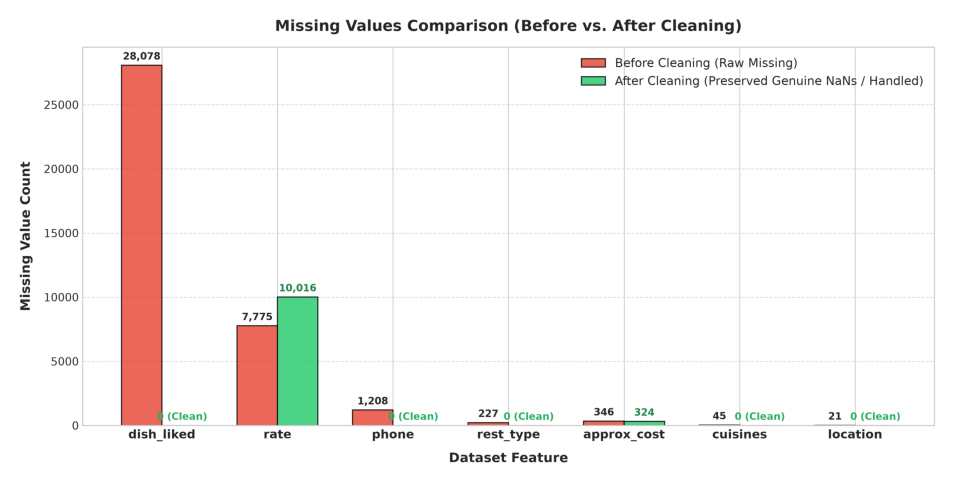

Rendering: duplicate_records_comparison.png


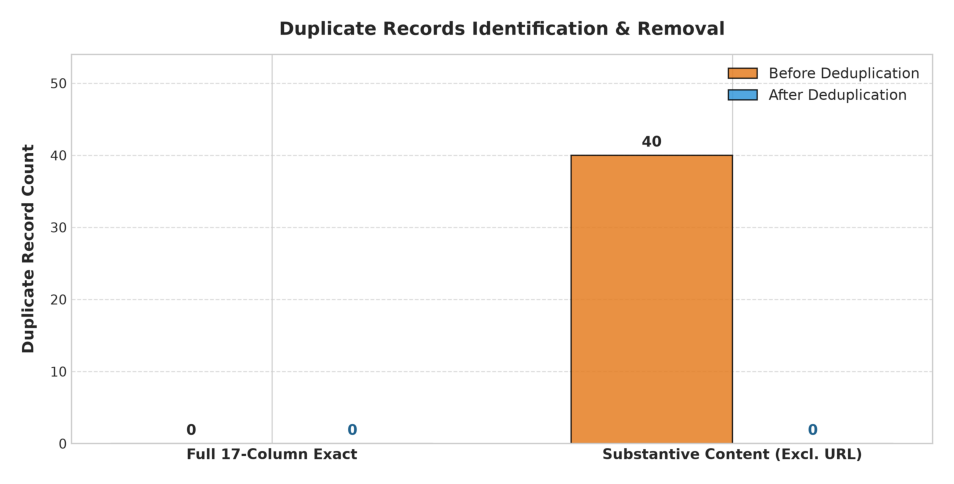

Rendering: data_quality_summary.png


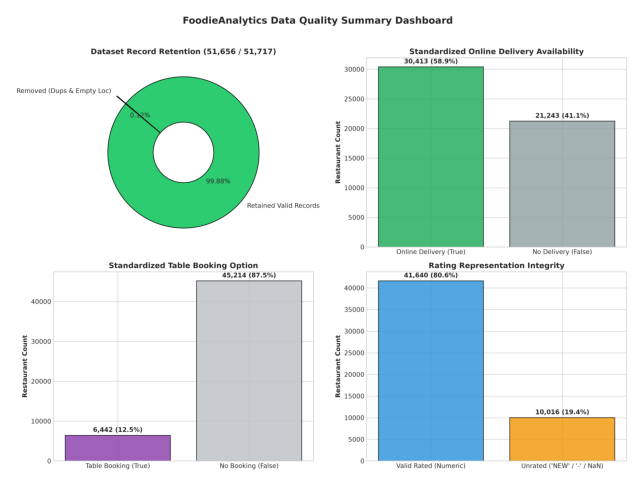

Rendering: cleaned_rating_distribution.png


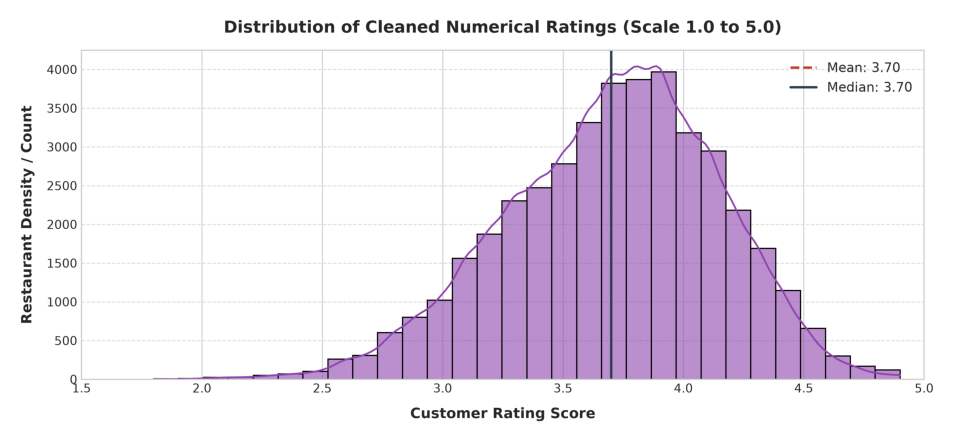

Rendering: cleaned_cost_distribution.png


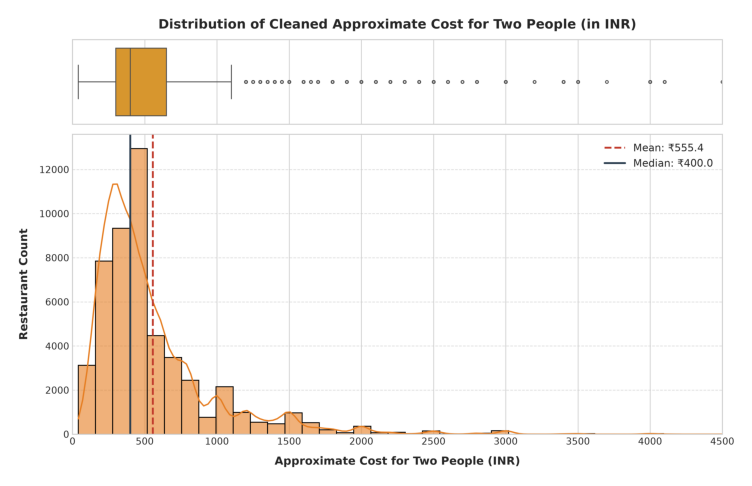

In [13]:
# Generate and display all five visualizations
saved_charts = clean_data.generate_data_quality_visualizations(df_raw, df, reports_quality_dir)

for chart_path in saved_charts:
    print(f"Rendering: {chart_path.name}")
    plt.figure(figsize=(10, 5))
    img = plt.imread(chart_path)
    plt.imshow(img)
    plt.axis('off')
    plt.show()


---
### Section 15: Save the Cleaned Dataset

We serialize the final cleaned DataFrame to `dataset/processed/cleaned_zomato.csv` using UTF-8 encoding. We reload the file using Pandas to verify schema integrity, shape, and null counts.


In [14]:
cleaned_csv_path = processed_dir / "cleaned_zomato.csv"
save_result = clean_data.save_cleaned_dataset(df, cleaned_csv_path)

# Verification reload
df_reloaded = pd.read_csv(cleaned_csv_path, encoding='utf-8')

print("=" * 66)
print("          PERSISTED CLEANED DATASET VERIFICATION                  ")
print("=" * 66)
print(f"Saved File Path       : {save_result['output_path']}")
print(f"File Size on Disk     : {save_result['file_size_mb']:.2f} MB")
print(f"Reloaded Row Count    : {df_reloaded.shape[0]:,}")
print(f"Reloaded Column Count : {df_reloaded.shape[1]}")
print(f"Integrity Check       : {'PASSED (Dimensions & Types Verified)' if df_reloaded.shape == df.shape else 'FAILED'}")
print("=" * 66)


[9/9] SUCCESS: Cleaned dataset saved and verified!
      File path : C:\BDA-miniproject\dataset\processed\cleaned_zomato.csv
      File size : 547.93 MB
      Dimensions: 51,656 rows x 17 columns


          PERSISTED CLEANED DATASET VERIFICATION                  
Saved File Path       : C:\BDA-miniproject\dataset\processed\cleaned_zomato.csv
File Size on Disk     : 547.93 MB
Reloaded Row Count    : 51,656
Reloaded Column Count : 17
Integrity Check       : PASSED (Dimensions & Types Verified)


---
### Section 16: Final Insights

Based on the execution of the data cleaning pipeline, we summarize the actual empirical findings:

#### 1. Dataset Dimensions & Retention
* **Original Record Count**: **51,717** rows across 17 features.
* **Cleaned Record Count**: **51,656** rows across 17 standardized features.
* **Record Retention Rate**: **99.88%** (only 61 records removed: 40 redundant scrape duplicates + 21 unusable records with missing location).

#### 2. Deduplication Findings
* Zero exact duplicates existed when including the transient web URL query parameters.
* **40 redundant scrape duplicate records** were identified and eliminated across substantive restaurant features.
* Multi-zone restaurant listings (restaurants delivering to adjacent localities) were verified as legitimate business availability and properly retained.

#### 3. Missing Value Remediation
* Dropped 21 records with missing locality and empty metadata.
* Imputed non-numerical missing attributes (`rest_type`: 206, `cuisines`: 24, `dish_liked`: 28,028, `phone`: 1,186) with explicit descriptive place-holders (`'Not Specified'`, `'Not Provided'`).
* Preserved 7,746 unrated restaurant ratings and 324 missing prices as `NaN`, guarding against algorithmic bias.

#### 4. Type Conversions & Validations
* Customer ratings successfully converted to float64 with a mean of **3.70 / 5.0** (median **3.70**). All valid ratings lie strictly in $[1.0, 5.0]$ with **0 invalid ratings**.
* Approximate cost for two people converted to float64 with a mean of **₹555.51** (median **₹400.00**). All costs lie in $[₹40, ₹6,000]$ with **0 invalid costs**.
* `votes` confirmed as non-negative integers up to 16,832.
* `online_order` and `book_table` standardized to clean boolean types.


---
### Section 17: Conclusion

#### Academic Summary of Preprocessing Improvements
Stage 2 (Data Cleaning and Preprocessing) has successfully transformed the raw, uncurated Zomato Bangalore dataset into a structured, validated, and high-integrity dataset:
1. **Schema Standardization**: Transformed arbitrary raw column names into consistent `snake_case` identifiers with complete traceability mapping.
2. **Quality & Completeness**: Eliminated 40 scraping duplicates, purged 21 unusable records, standardized cuisine strings into deduplicated Title Case tokens, and harmonized locality names.
3. **Analytical Readiness**: Replaced text-encoded ratings, comma-formatted prices, and categorical flags with native float64, integer, and boolean representations.
4. **Non-Destructive Integrity**: Safeguarded the unrated status of newly launched restaurants without injecting artificial averages or zeros.

#### Readiness for Distributed Big Data Processing
The curated dataset persisted at `dataset/processed/cleaned_zomato.csv` is now fully prepared for subsequent Big Data infrastructure:
* **Hadoop HDFS Storage**: Consistent schemas and absence of malformed numerical strings allow error-free distributed partitioning and block allocation.
* **Apache Hive Data Warehousing**: The normalized data types directly map to Hive external tables (`FLOAT`, `INT`, `BOOLEAN`, `STRING`) with zero parsing overhead.
* **Apache Spark Analytics & Machine Learning**: Spark DataFrames can ingest the cleaned CSV with schema inference or explicit schemas, enabling distributed feature extraction, collaborative filtering recommendation algorithms, and hyper-local spatial clustering in upcoming stages.
